# Часть 7 из 8. Эксперименты с нейросетями

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- архитектуры Wide & Deep, Multi-Head Attention и TabNet;
- кривые ошибки на валидации по эпохам;
- повторное обучение ансамбля бустингов, веса сохраняются в `best_weights.npy`.

**Главный результат:** нейросети уступают бустингам: лучшая — базовая NN v1 (MAPE 8,17 %), Wide & Deep — 10,28 %, TabNet — 11,11 %, Attention — 12,16 %.

**Графики для отчёта:**
- рисунок 6 — сравнение архитектур нейросетей: ошибка на валидации по эпохам: [`figures/fig_06_nn_validation_loss.png`](figures/fig_06_nn_validation_loss.png)

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–6 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 6. Ансамбль CatBoost, LightGBM и XGBoost](06_ensemble.ipynb) · [Все части](README.md) · [Часть 8. Важность признаков, проверка на тесте и финальная модель](08_final_model.ipynb) →

### Эксперементы с нейросетями

In [81]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
import matplotlib.pyplot as plt
import time

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

TARGET = 'price_rub'
df_nn = df_sec_m.copy()

bad = [c for c in df_nn.columns
       if isinstance(df_nn[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_nn[c])]
df_nn = df_nn.drop(columns=bad)

multi_cat_cols = [c for c in ['district', 'okrug', 'metro_station',
                              'metro_line', 'building_type', 'renovation']
                  if c in df_nn.columns]
cyclic_cols = [c for c in ['month_sin', 'month_cos', 'dow_sin', 'dow_cos']
               if c in df_nn.columns]
bin_cols = [c for c in ['has_balcony', 'metro_distance_type', 'seller_type']
            if c in df_nn.columns]

excluded = set(multi_cat_cols + cyclic_cols + bin_cols + [TARGET])
num_cols = [c for c in df_nn.columns if c not in excluded]

cat_cardinalities = {}
for c in multi_cat_cols:
    df_nn[c] = df_nn[c].astype('category')
    cat_cardinalities[c] = len(df_nn[c].cat.categories)
    df_nn[c] = df_nn[c].cat.codes.astype('int64')

idx_tr, idx_tmp = train_test_split(df_nn.index, test_size=0.3, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=42)

medians = df_nn.loc[idx_tr, num_cols].median()
qt = QuantileTransformer(output_distribution='normal',
                         n_quantiles=min(1000, len(idx_tr)),
                         random_state=42)

X_num_tr  = qt.fit_transform(df_nn.loc[idx_tr,  num_cols].fillna(medians)).astype('float32')
X_num_val = qt.transform(    df_nn.loc[idx_val, num_cols].fillna(medians)).astype('float32')

X_bin_tr  = df_nn.loc[idx_tr,  bin_cols].fillna(0).astype('float32').values
X_bin_val = df_nn.loc[idx_val, bin_cols].fillna(0).astype('float32').values

X_cyc_tr  = df_nn.loc[idx_tr,  cyclic_cols].astype('float32').values
X_cyc_val = df_nn.loc[idx_val, cyclic_cols].astype('float32').values

X_cat_tr  = df_nn.loc[idx_tr,  multi_cat_cols].values.astype('int64')
X_cat_val = df_nn.loc[idx_val, multi_cat_cols].values.astype('int64')

y_tr  = np.log1p(df_nn.loc[idx_tr,  TARGET].values).astype('float32')
y_val = np.log1p(df_nn.loc[idx_val, TARGET].values).astype('float32')

X_cont_tr  = np.hstack([X_num_tr,  X_bin_tr,  X_cyc_tr])
X_cont_val = np.hstack([X_num_val, X_bin_val, X_cyc_val])

n_cont = X_cont_tr.shape[1]
card_list = [cat_cardinalities[c] for c in multi_cat_cols]
print(f"n_cont={n_cont}, card_list={card_list}")

Device: cuda
n_cont=21, card_list=[129, 11, 104, 12, 6, 4]


In [82]:
def train_model(model, name, epochs=100, batch_size=512, lr=5e-4,
                weight_decay=5e-5, patience=15, delta=1.0):
    """Обучает модель и возвращает метрики + историю."""

    train_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_cont_tr), torch.from_numpy(X_cat_tr),
            torch.from_numpy(y_tr)),
        batch_size=batch_size, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_cont_val), torch.from_numpy(X_cat_val),
            torch.from_numpy(y_val)),
        batch_size=batch_size, shuffle=False
    )

    criterion = nn.HuberLoss(delta=delta)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_val, wait = float('inf'), 0
    history = {'train': [], 'val': []}
    t0 = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for xc, xk, yt in train_loader:
            xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xc, xk), yt)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * xc.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xc, xk, yt in val_loader:
                xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
                val_loss += criterion(model(xc, xk), yt).item() * xc.size(0)
        val_loss /= len(val_loader.dataset)

        scheduler.step()
        history['train'].append(train_loss)
        history['val'].append(val_loss)

        if val_loss < best_val:
            best_val, wait = val_loss, 0
            torch.save(model.state_dict(), f'{name}.pt')
        else:
            wait += 1
            if wait >= patience:
                break

    # Метрики
    model.load_state_dict(torch.load(f'{name}.pt'))
    model.eval()
    preds = []
    with torch.no_grad():
        for xc, xk, _ in val_loader:
            xc, xk = xc.to(device), xk.to(device)
            preds.append(model(xc, xk).cpu().numpy())
    pred_log = np.concatenate(preds)
    pred = np.expm1(pred_log)
    true = np.expm1(y_val)

    mape = np.mean(np.abs((pred - true) / true)) * 100
    r2   = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)
    mae  = np.mean(np.abs(pred - true))

    print(f"\n=== {name} ===")
    print(f"MAPE: {mape:.3f}% | R²: {r2:.4f} | MAE: {mae:,.0f} | time: {time.time()-t0:.0f}s")

    return {'name': name, 'mape': mape, 'r2': r2, 'mae': mae,
            'pred': pred, 'history': history}

In [83]:
# Эксперемент 1 Wide & Deep
class WideAndDeep(nn.Module):
    def __init__(self, n_cont, cat_cardinalities, hidden=256, emb_dropout=0.1):
        super().__init__()
        self.embs = nn.ModuleList([
            nn.Embedding(card, min(64, (card + 1) // 2))
            for card in cat_cardinalities
        ])
        emb_dim = sum(e.embedding_dim for e in self.embs)
        total_in = n_cont + emb_dim

        # Wide — линейная часть
        self.wide = nn.Linear(total_in, 1)

        # Deep — нелинейная
        self.emb_dropout = nn.Dropout(emb_dropout)
        self.deep = nn.Sequential(
            nn.Linear(total_in, hidden),
            nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden, hidden // 2),
            nn.BatchNorm1d(hidden // 2), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x_cont, x_cat):
        embs = [e(x_cat[:, i]) for i, e in enumerate(self.embs)]
        x = torch.cat([x_cont, self.emb_dropout(torch.cat(embs, dim=1))], dim=1)
        return (self.wide(x) + self.deep(x)).squeeze(-1)


torch.manual_seed(42)
model_wd = WideAndDeep(n_cont, card_list).to(device)
res_wd = train_model(model_wd, 'nn_widedeep')


=== nn_widedeep ===
MAPE: 10.281% | R²: 0.9461 | MAE: 1,326,251 | time: 74s


In [84]:
# Эксперемент 2 Multi-Head Attention
class AttentionNet(nn.Module):
    def __init__(self, n_cont, cat_cardinalities, d_model=64, nhead=4,
                 num_layers=2, hidden=128, emb_dropout=0.1):
        super().__init__()

        # Все категориальные — в одно d_model пространство
        self.embs = nn.ModuleList([
            nn.Embedding(card, d_model) for card in cat_cardinalities
        ])
        n_cat = len(cat_cardinalities)

        # Проекция непрерывных в d_model — станет "токеном"
        self.cont_proj = nn.Linear(n_cont, d_model)
        self.n_tokens = n_cat + 1  # каждая категория + непрерывные

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4,
            dropout=0.1, batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Выход
        self.head = nn.Sequential(
            nn.Linear(d_model * self.n_tokens, hidden),
            nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden, 1),
        )

    def forward(self, x_cont, x_cat):
        # Непрерывные → один токен
        cont_token = self.cont_proj(x_cont).unsqueeze(1)  # (B, 1, d)
        # Категориальные → отдельные токены
        cat_tokens = torch.stack(
            [e(x_cat[:, i]) for i, e in enumerate(self.embs)], dim=1
        )  # (B, n_cat, d)
        # Собираем последовательность
        tokens = torch.cat([cont_token, cat_tokens], dim=1)  # (B, n_tokens, d)
        # Transformer
        out = self.transformer(tokens)  # (B, n_tokens, d)
        # Flatten и в голову
        out = out.reshape(out.size(0), -1)
        return self.head(out).squeeze(-1)


torch.manual_seed(42)
model_attn = AttentionNet(n_cont, card_list).to(device)
res_attn = train_model(model_attn, 'nn_attention', lr=3e-4, epochs=150)


=== nn_attention ===
MAPE: 12.163% | R²: 0.8925 | MAE: 1,700,874 | time: 21s


In [85]:
# Эксперемент 3 TabNet
from pytorch_tabnet.tab_model import TabNetRegressor

# TabNet хочет всё в одну матрицу
X_tr_tab = np.hstack([X_cont_tr, X_cat_tr]).astype('float32')
X_val_tab = np.hstack([X_cont_val, X_cat_val]).astype('float32')

# Для TabNet категориальные — не эмбеддинги, а "categorical_idx"
cat_idxs = list(range(n_cont, n_cont + len(cat_cardinalities)))
cat_dims = card_list

tabnet = TabNetRegressor(
    n_d=32, n_a=32, n_steps=5,
    gamma=1.5, n_independent=2, n_shared=2,
    cat_idxs=cat_idxs, cat_dims=cat_dims,
    cat_emb_dim=3,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-3),
    scheduler_params=dict(step_size=20, gamma=0.9),
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type='entmax',
    seed=42, verbose=10,
)

tabnet.fit(
    X_train=X_tr_tab, y_train=y_tr.reshape(-1, 1),
    eval_set=[(X_val_tab, y_val.reshape(-1, 1))],
    eval_metric=['mae'],
    max_epochs=200, patience=30,
    batch_size=1024, virtual_batch_size=128,
    num_workers=0,
    drop_last=False,
)

# Метрики
pred_tab = tabnet.predict(X_val_tab).flatten()
pred = np.expm1(pred_tab)
true = np.expm1(y_val)
mape_tab = np.mean(np.abs((pred - true) / true)) * 100
r2_tab   = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)

print(f"\n=== TabNet ===")
print(f"MAPE: {mape_tab:.3f}% | R²: {r2_tab:.4f}")

res_tabnet = {'name': 'TabNet', 'mape': mape_tab, 'r2': r2_tab, 'pred': pred}

c:\Users\Computer\Desktop\programInj\house-price-predictor-\venv\lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 157.41482| val_0_mae: 9.50175 |  0:00:03s
epoch 10 | loss: 0.26075 | val_0_mae: 0.36568 |  0:00:37s
epoch 20 | loss: 0.15969 | val_0_mae: 0.28808 |  0:01:10s
epoch 30 | loss: 0.12277 | val_0_mae: 0.24958 |  0:02:20s
epoch 40 | loss: 0.10322 | val_0_mae: 0.23948 |  0:02:58s
epoch 50 | loss: 0.08426 | val_0_mae: 0.20317 |  0:03:30s
epoch 60 | loss: 0.0733  | val_0_mae: 0.20083 |  0:04:02s
epoch 70 | loss: 0.0661  | val_0_mae: 0.18541 |  0:04:34s
epoch 80 | loss: 0.05728 | val_0_mae: 0.17114 |  0:05:06s
epoch 90 | loss: 0.05019 | val_0_mae: 0.1653  |  0:05:38s
epoch 100| loss: 0.04617 | val_0_mae: 0.15539 |  0:06:10s
epoch 110| loss: 0.04147 | val_0_mae: 0.14801 |  0:06:41s
epoch 120| loss: 0.03896 | val_0_mae: 0.14813 |  0:07:12s
epoch 130| loss: 0.03716 | val_0_mae: 0.13885 |  0:07:44s
epoch 140| loss: 0.0346  | val_0_mae: 0.13199 |  0:08:17s
epoch 150| loss: 0.03238 | val_0_mae: 0.13239 |  0:08:49s
epoch 160| loss: 0.0303  | val_0_mae: 0.12421 |  0:09:21s
epoch 170| lo

c:\Users\Computer\Desktop\programInj\house-price-predictor-\venv\lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



=== TabNet ===
MAPE: 11.110% | R²: 0.9289


In [86]:
all_results = [res_wd, res_attn, res_tabnet]

# Добавьте сюда свой baseline из прошлого запуска
baseline_nn = {'name': 'NN v1 (baseline)', 'mape': 8.17, 'r2': 0.9655}

results_df = pd.DataFrame([
    {'name': baseline_nn['name'], 'mape': baseline_nn['mape'], 'r2': baseline_nn['r2']},
    *[{'name': r['name'], 'mape': r['mape'], 'r2': r['r2']} for r in all_results],
]).sort_values('mape')

print(results_df.to_string(index=False))

            name      mape       r2
NN v1 (baseline)  8.170000 0.965500
     nn_widedeep 10.280665 0.946125
          TabNet 11.110476 0.928910
    nn_attention 12.163381 0.892507


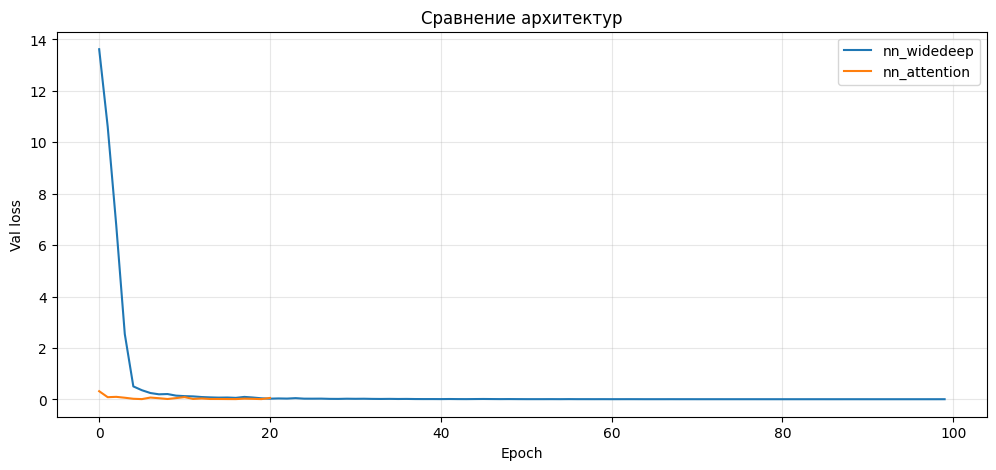

In [87]:
plt.figure(figsize=(12, 5))
for r in all_results:
    if 'history' in r:
        plt.plot(r['history']['val'], label=r['name'])
plt.xlabel('Epoch')
plt.ylabel('Val loss')
plt.legend()
plt.title('Сравнение архитектур')
plt.grid(alpha=0.3)
plt.show()

In [90]:
fe_features = ['dist_kremlin', 'dist_msk_city', 'dist_vdnkh', 'dist_luzhniki',
               'area_per_room', 'kitchen_share', 'living_share',
               'ceiling_per_area', 'district_avg_area', 'district_avg_age',
               'station_avg_area']

print("В df_sec_m:", [c for c in fe_features if c in df_sec_m.columns])
print("В df_cb:",    [c for c in fe_features if c in df_cb.columns])

В df_sec_m: ['living_share']
В df_cb: ['dist_kremlin', 'dist_msk_city', 'dist_vdnkh', 'dist_luzhniki', 'area_per_room', 'kitchen_share', 'living_share', 'ceiling_per_area', 'district_avg_area', 'district_avg_age', 'station_avg_area']


In [ ]:
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
import lightgbm as lgb
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ============================================================
# 1. ДАННЫЕ (те же 70/15/15, что и везде)
# ============================================================

TARGET = 'price_rub'
df_ens = df_cb.copy()

bad = [c for c in df_ens.columns
       if isinstance(df_ens[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_ens[c])]
df_ens = df_ens.drop(columns=bad)

cat_cols = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                        'building_type', 'renovation']
            if c in df_ens.columns]

X = df_ens.drop(columns=[TARGET])
y = np.log1p(df_ens[TARGET].values)

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

print(f"train: {X_tr.shape}, val: {X_val.shape}, test: {X_test.shape}")

# ============================================================
# 2. CatBoost с best_params от Optuna
# ============================================================

X_tr_cb = X_tr.copy(); X_val_cb = X_val.copy()
for c in cat_cols:
    X_tr_cb[c]  = X_tr_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)

cat_idx = [X_tr_cb.columns.get_loc(c) for c in cat_cols]

model_cb = CatBoostRegressor(
    iterations=10000, learning_rate=0.0290398, depth=7, l2_leaf_reg=4.14278,
    bagging_temperature=0.104705, random_strength=0.198779,
    loss_function='RMSE', eval_metric='MAPE',
    random_seed=42, early_stopping_rounds=300, verbose=500,
    cat_features=cat_idx,
)
t0 = time.time()
model_cb.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val), use_best_model=True)
print(f"\nCatBoost: {time.time()-t0:.1f} сек")
pred_cb_val = model_cb.predict(X_val_cb)

# ============================================================
# 3. LightGBM
# ============================================================

X_tr_lgb = X_tr.copy(); X_val_lgb = X_val.copy()
for c in cat_cols:
    X_tr_lgb[c]  = X_tr_lgb[c].astype('category')
    X_val_lgb[c] = X_val_lgb[c].astype('category')

model_lgb = lgb.LGBMRegressor(
    n_estimators=5000, learning_rate=0.03, num_leaves=63,
    min_child_samples=20, reg_alpha=0.1, reg_lambda=0.1,
    random_state=42, n_jobs=-1, verbose=-1,
)
t0 = time.time()
model_lgb.fit(
    X_tr_lgb, y_tr,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric='mape',
    callbacks=[lgb.early_stopping(200, verbose=False)],
)
print(f"LightGBM: {time.time()-t0:.1f} сек")
pred_lgb_val = model_lgb.predict(X_val_lgb)

# ============================================================
# 4. XGBoost
# ============================================================

X_tr_xgb = X_tr.copy(); X_val_xgb = X_val.copy()
for c in cat_cols:
    X_tr_xgb[c]  = X_tr_xgb[c].astype('category')
    X_val_xgb[c] = X_val_xgb[c].astype('category')

model_xgb = xgb.XGBRegressor(
    n_estimators=5000, learning_rate=0.03, max_depth=8,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42,
    tree_method='hist', enable_categorical=True,
    early_stopping_rounds=200, verbosity=0,
)
t0 = time.time()
model_xgb.fit(X_tr_xgb, y_tr, eval_set=[(X_val_xgb, y_val)], verbose=False)
print(f"XGBoost: {time.time()-t0:.1f} сек")
pred_xgb_val = model_xgb.predict(X_val_xgb)

# ============================================================
# 5. МЕТРИКИ И АНСАМБЛИ
# ============================================================

def mape_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return np.mean(np.abs((pred - true) / true)) * 100

print("\n=== Одиночные модели ===")
print(f"CatBoost: {mape_log(pred_cb_val,  y_val):.3f}%")
print(f"LightGBM: {mape_log(pred_lgb_val, y_val):.3f}%")
print(f"XGBoost:  {mape_log(pred_xgb_val, y_val):.3f}%")

# Простое среднее
pred_avg = (pred_cb_val + pred_lgb_val + pred_xgb_val) / 3
print(f"\nПростое среднее: {mape_log(pred_avg, y_val):.3f}%")

# Взвешенное — Optuna подбирает веса
def objective(trial):
    w = np.array([trial.suggest_float(f'w{i}', 0, 1) for i in range(3)])
    w = w / w.sum()
    pred_log = w[0]*pred_cb_val + w[1]*pred_lgb_val + w[2]*pred_xgb_val
    return mape_log(pred_log, y_val)

study_ens = optuna.create_study(direction='minimize')
study_ens.optimize(objective, n_trials=100)

w = np.array([study_ens.best_params[f'w{i}'] for i in range(3)])
w = w / w.sum()
print(f"\nЛучшие веса: CB={w[0]:.3f}, LGB={w[1]:.3f}, XGB={w[2]:.3f}")

pred_w = w[0]*pred_cb_val + w[1]*pred_lgb_val + w[2]*pred_xgb_val
print(f"Взвешенное среднее: {mape_log(pred_w, y_val):.3f}%")

# ============================================================
# 6. ИТОГ
# ============================================================

results = pd.DataFrame({
    'Модель': ['CatBoost', 'LightGBM', 'XGBoost',
               'Простое среднее', 'Взвешенное среднее'],
    'MAPE %': [
        mape_log(pred_cb_val, y_val),
        mape_log(pred_lgb_val, y_val),
        mape_log(pred_xgb_val, y_val),
        mape_log(pred_avg, y_val),
        mape_log(pred_w, y_val),
    ],
}).sort_values('MAPE %')

print("\n=== ИТОГ ===")
print(results.to_string(index=False))

# Сохраняем лучшие веса и предсказания для test
np.save('best_weights.npy', w)
print(f"\nВеса сохранены в best_weights.npy")

train: (35000, 41), val: (7500, 41), test: (7500, 41)
0:	learn: 0.0293425	test: 0.0290609	best: 0.0290609 (0)	total: 79ms	remaining: 13m 9s
500:	learn: 0.0043723	test: 0.0042898	best: 0.0042898 (500)	total: 38.6s	remaining: 12m 11s
1000:	learn: 0.0040523	test: 0.0041502	best: 0.0041502 (1000)	total: 1m 15s	remaining: 11m 18s
1500:	learn: 0.0038775	test: 0.0041225	best: 0.0041225 (1500)	total: 1m 53s	remaining: 10m 42s
2000:	learn: 0.0037359	test: 0.0041107	best: 0.0041107 (1996)	total: 2m 29s	remaining: 9m 58s
2500:	learn: 0.0036088	test: 0.0041078	best: 0.0041077 (2491)	total: 3m 6s	remaining: 9m 19s
3000:	learn: 0.0034826	test: 0.0041055	best: 0.0041049 (2963)	total: 3m 46s	remaining: 8m 47s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.004104905276
bestIteration = 2963

Shrink model to first 2964 iterations.

CatBoost: 248.4 сек


c:\Users\Computer\Desktop\programInj\house-price-predictor-\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM: 2.4 сек
XGBoost: 5.0 сек

=== Одиночные модели ===
CatBoost: 6.673%
LightGBM: 7.223%
XGBoost:  8.226%

Простое среднее: 7.025%

Лучшие веса: CB=0.904, LGB=0.095, XGB=0.001
Взвешенное среднее: 6.664%

=== ИТОГ ===
            Модель   MAPE %
Взвешенное среднее 6.664445
          CatBoost 6.672555
   Простое среднее 7.024756
          LightGBM 7.223498
           XGBoost 8.225806

Веса сохранены в best_weights.npy


---
← [Часть 6. Ансамбль CatBoost, LightGBM и XGBoost](06_ensemble.ipynb) · [Все части](README.md) · [Часть 8. Важность признаков, проверка на тесте и финальная модель](08_final_model.ipynb) →